# Uji Stasioneritas Data Kunjungan Harian (jk)

In [5]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [6]:
PATH = r"C:\Users\Aurel Maritza\OneDrive\ドキュメント\A. KULIAH\SEM 5\ADW\peramalan-kunjungan-harian\data\Harian Total 2023 sd 2026.xlsx"
KOLOM = "jk"
WINDOW = 30

df = pd.read_excel(PATH)
df["tanggal"] = pd.to_datetime(df["tanggal"])
y = df.set_index("tanggal")[KOLOM].asfreq("D")

print(y.shape, y.index.min().date(), y.index.max().date(), y.isna().sum())
y.head()

(1382,) 2023-01-01 2026-10-13 0


tanggal
2023-01-01     149
2023-01-02    1015
2023-01-03    1685
2023-01-04     770
2023-01-05     811
Freq: D, Name: jk, dtype: int64

## Uji hipotesis

In [7]:
def kesimpulan(p, h0_stasioner):
    if h0_stasioner:
        return "Tolak H0, tidak stasioner" if p < 0.05 else "Gagal tolak H0, stasioner"
    return "Tolak H0, stasioner" if p < 0.05 else "Gagal tolak H0, tidak stasioner"


def uji(seri, nama):
    seri = seri.dropna()
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(seri, autolag="AIC")
    kpss_c, kpss_c_p, _, kpss_c_crit = kpss(seri, regression="c", nlags="auto")
    kpss_t, kpss_t_p, _, kpss_t_crit = kpss(seri, regression="ct", nlags="auto")
    return [
        [nama, "ADF", "Ada unit root (tidak stasioner)", adf_stat, adf_crit["5%"], adf_p, kesimpulan(adf_p, False)],
        [nama, "KPSS (level)", "Stasioner di sekitar level", kpss_c, kpss_c_crit["5%"], kpss_c_p, kesimpulan(kpss_c_p, True)],
        [nama, "KPSS (trend)", "Stasioner di sekitar tren", kpss_t, kpss_t_crit["5%"], kpss_t_p, kesimpulan(kpss_t_p, True)],
    ]


kolom = ["Data", "Uji", "Hipotesis nol (H0)", "Statistik uji", "Nilai kritis 5%", "p-value", "Kesimpulan"]
baris = uji(y, f"{KOLOM} asli") + uji(y.diff(7), f"{KOLOM} diff musiman (lag 7)")
tabel_uji = pd.DataFrame(baris, columns=kolom)
tabel_uji.round(4)

,Data,Uji,Hipotesis nol (H0),Statistik uji,Nilai kritis 5%,p-value,Kesimpulan
0,jk asli,ADF,Ada unit root (tidak stasioner),-5.1132,-2.8637,0.0000,"Tolak H0, stasioner"
1,jk asli,KPSS (level),Stasioner di sekitar level,1.9244,0.4630,0.0100,"Tolak H0, tidak stasioner"
2,jk asli,KPSS (trend),Stasioner di sekitar tren,0.2035,0.1460,0.0147,"Tolak H0, tidak stasioner"
3,jk diff musiman (lag 7),ADF,Ada unit root (tidak stasioner),-12.9414,-2.8637,0.0000,"Tolak H0, stasioner"
4,jk diff musiman (lag 7),KPSS (level),Stasioner di sekitar level,0.0050,0.4630,0.1000,"Gagal tolak H0, stasioner"
5,jk diff musiman (lag 7),KPSS (trend),Stasioner di sekitar tren,0.0043,0.1460,0.1000,"Gagal tolak H0, stasioner"


## Visualisasi bukti ketidakstasioneran

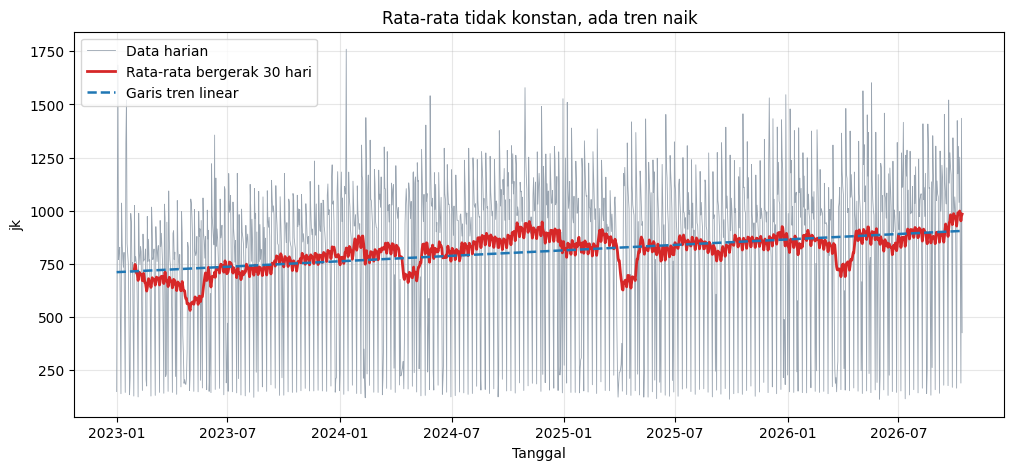

In [8]:
rata = y.rolling(WINDOW).mean()
simpang = y.rolling(WINDOW).std()

t = np.arange(len(y))
koef = np.polyfit(t, y.values, 1)
garis_tren = np.polyval(koef, t)

fig, ax = plt.subplots()
ax.plot(y.index, y.values, color="#9aa5b1", lw=0.6, label="Data harian")
ax.plot(rata.index, rata.values, color="#d62728", lw=2, label=f"Rata-rata bergerak {WINDOW} hari")
ax.plot(y.index, garis_tren, color="#1f77b4", lw=1.8, ls="--", label="Garis tren linear")
ax.set_title("Rata-rata tidak konstan, ada tren naik")
ax.set_xlabel("Tanggal")
ax.set_ylabel(KOLOM)
ax.legend(loc="upper left")
plt.show()

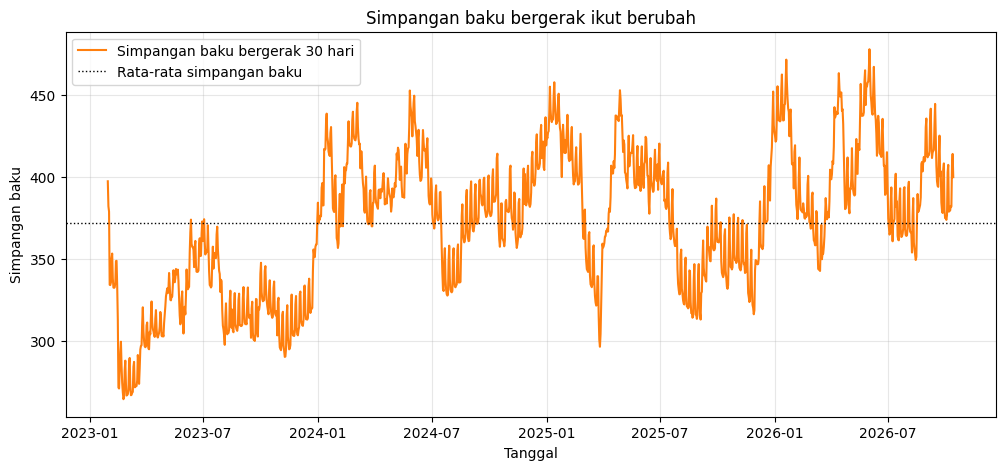

In [9]:
fig, ax = plt.subplots()
ax.plot(simpang.index, simpang.values, color="#ff7f0e", lw=1.5, label=f"Simpangan baku bergerak {WINDOW} hari")
ax.axhline(simpang.mean(), color="k", ls=":", lw=1, label="Rata-rata simpangan baku")
ax.set_title("Simpangan baku bergerak ikut berubah")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Simpangan baku")
ax.legend()
plt.show()

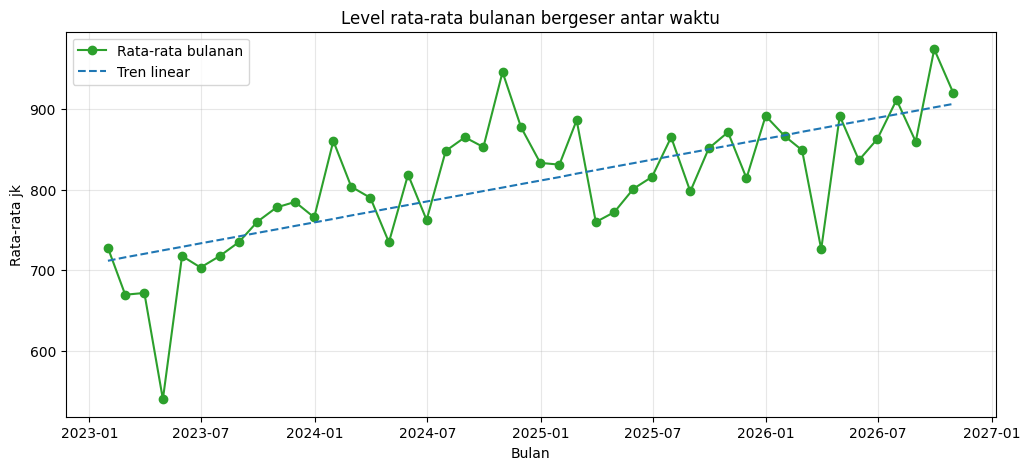

In [10]:
bulanan = y.resample("ME").mean()
tb = np.arange(len(bulanan))
koef_b = np.polyfit(tb, bulanan.values, 1)

fig, ax = plt.subplots()
ax.plot(bulanan.index, bulanan.values, marker="o", color="#2ca02c", lw=1.5, label="Rata-rata bulanan")
ax.plot(bulanan.index, np.polyval(koef_b, tb), color="#1f77b4", ls="--", label="Tren linear")
ax.set_title("Level rata-rata bulanan bergeser antar waktu")
ax.set_xlabel("Bulan")
ax.set_ylabel(f"Rata-rata {KOLOM}")
ax.legend()
plt.show()

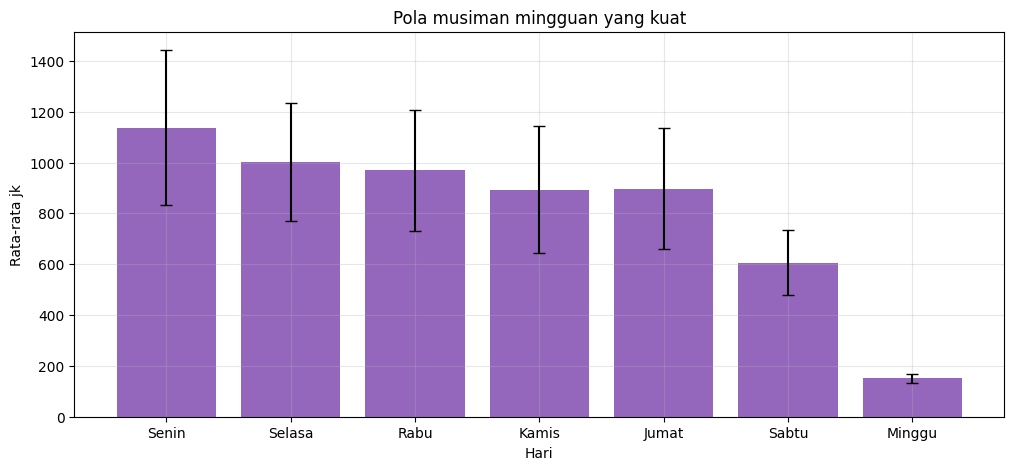

In [11]:
nama_hari = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
per_hari = y.groupby(y.index.dayofweek).agg(["mean", "std"])

fig, ax = plt.subplots()
ax.bar(nama_hari, per_hari["mean"], yerr=per_hari["std"], color="#9467bd", capsize=4)
ax.set_title("Pola musiman mingguan yang kuat")
ax.set_xlabel("Hari")
ax.set_ylabel(f"Rata-rata {KOLOM}")
plt.show()

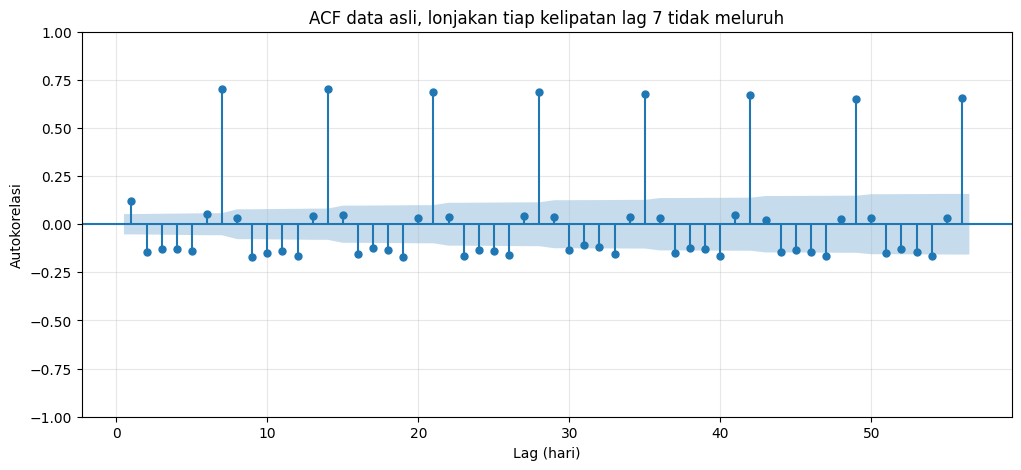

In [12]:
fig, ax = plt.subplots()
plot_acf(y.dropna(), lags=56, ax=ax, zero=False)
ax.set_title("ACF data asli, lonjakan tiap kelipatan lag 7 tidak meluruh")
ax.set_xlabel("Lag (hari)")
ax.set_ylabel("Autokorelasi")
plt.show()